## 1. Почему это feature extraction, а не fine-tuning

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from lawankz.rk2_week2 import run_week2_analysis

RESULTS_DIR = PROJECT_ROOT / "results" / "rk2_week2"
summary = run_week2_analysis(
    PROJECT_ROOT / "results" / "weeks_1_4" / "processed_articles.jsonl",
    RESULTS_DIR,
)
summary

{'week': 2,
 'task': 'Классификация статьи по исходному нормативному акту',
 'article_count': 306,
 'train_count': 229,
 'test_count': 77,
 'class_count': 6,
 'minimum_words': 20,
 'test_size': 0.25,
 'seed': 42,
 'model_name': 'cointegrated/rubert-tiny2',
 'model_revision': '776805cd8327870dc89ab911826f5e01462edb20',
 'bert_frozen': True,
 'bert_embedding_dimension': 312,
 'tfidf_vocabulary_size': 6834,
 'embedding_cache_used': True,
 'metrics': {'TF-IDF + Logistic Regression': {'accuracy': 0.8961,
   'precision_macro': 0.8902,
   'recall_macro': 0.8812,
   'f1_macro': 0.8844},
  'Frozen RuBERT + Logistic Regression': {'accuracy': 0.8571,
   'precision_macro': 0.8404,
   'recall_macro': 0.8735,
   'f1_macro': 0.8514}},
 'limitations': ['Метки получены из источника статьи, а не из ручной тематической разметки.',
  'Разбиение выполнено по статьям; формулировки одного акта встречаются и в train, и в test.',
  'BERT используется только как frozen feature extractor и ещё не адаптирован к з

## 2. Разбиение данных

In [ ]:
split = pd.read_csv(RESULTS_DIR / "dataset_split.csv")
pd.crosstab(split["document_id"], split["split"], margins=True)

## 3. Сравнение моделей

In [3]:
comparison = pd.read_csv(RESULTS_DIR / "model_comparison.csv")
comparison

,model,accuracy,precision_macro,recall_macro,f1_macro
0,TF-IDF + Logistic Regression,0.8961,0.8902,0.8812,0.8844
1,Frozen RuBERT + Logistic Regression,0.8571,0.8404,0.8735,0.8514


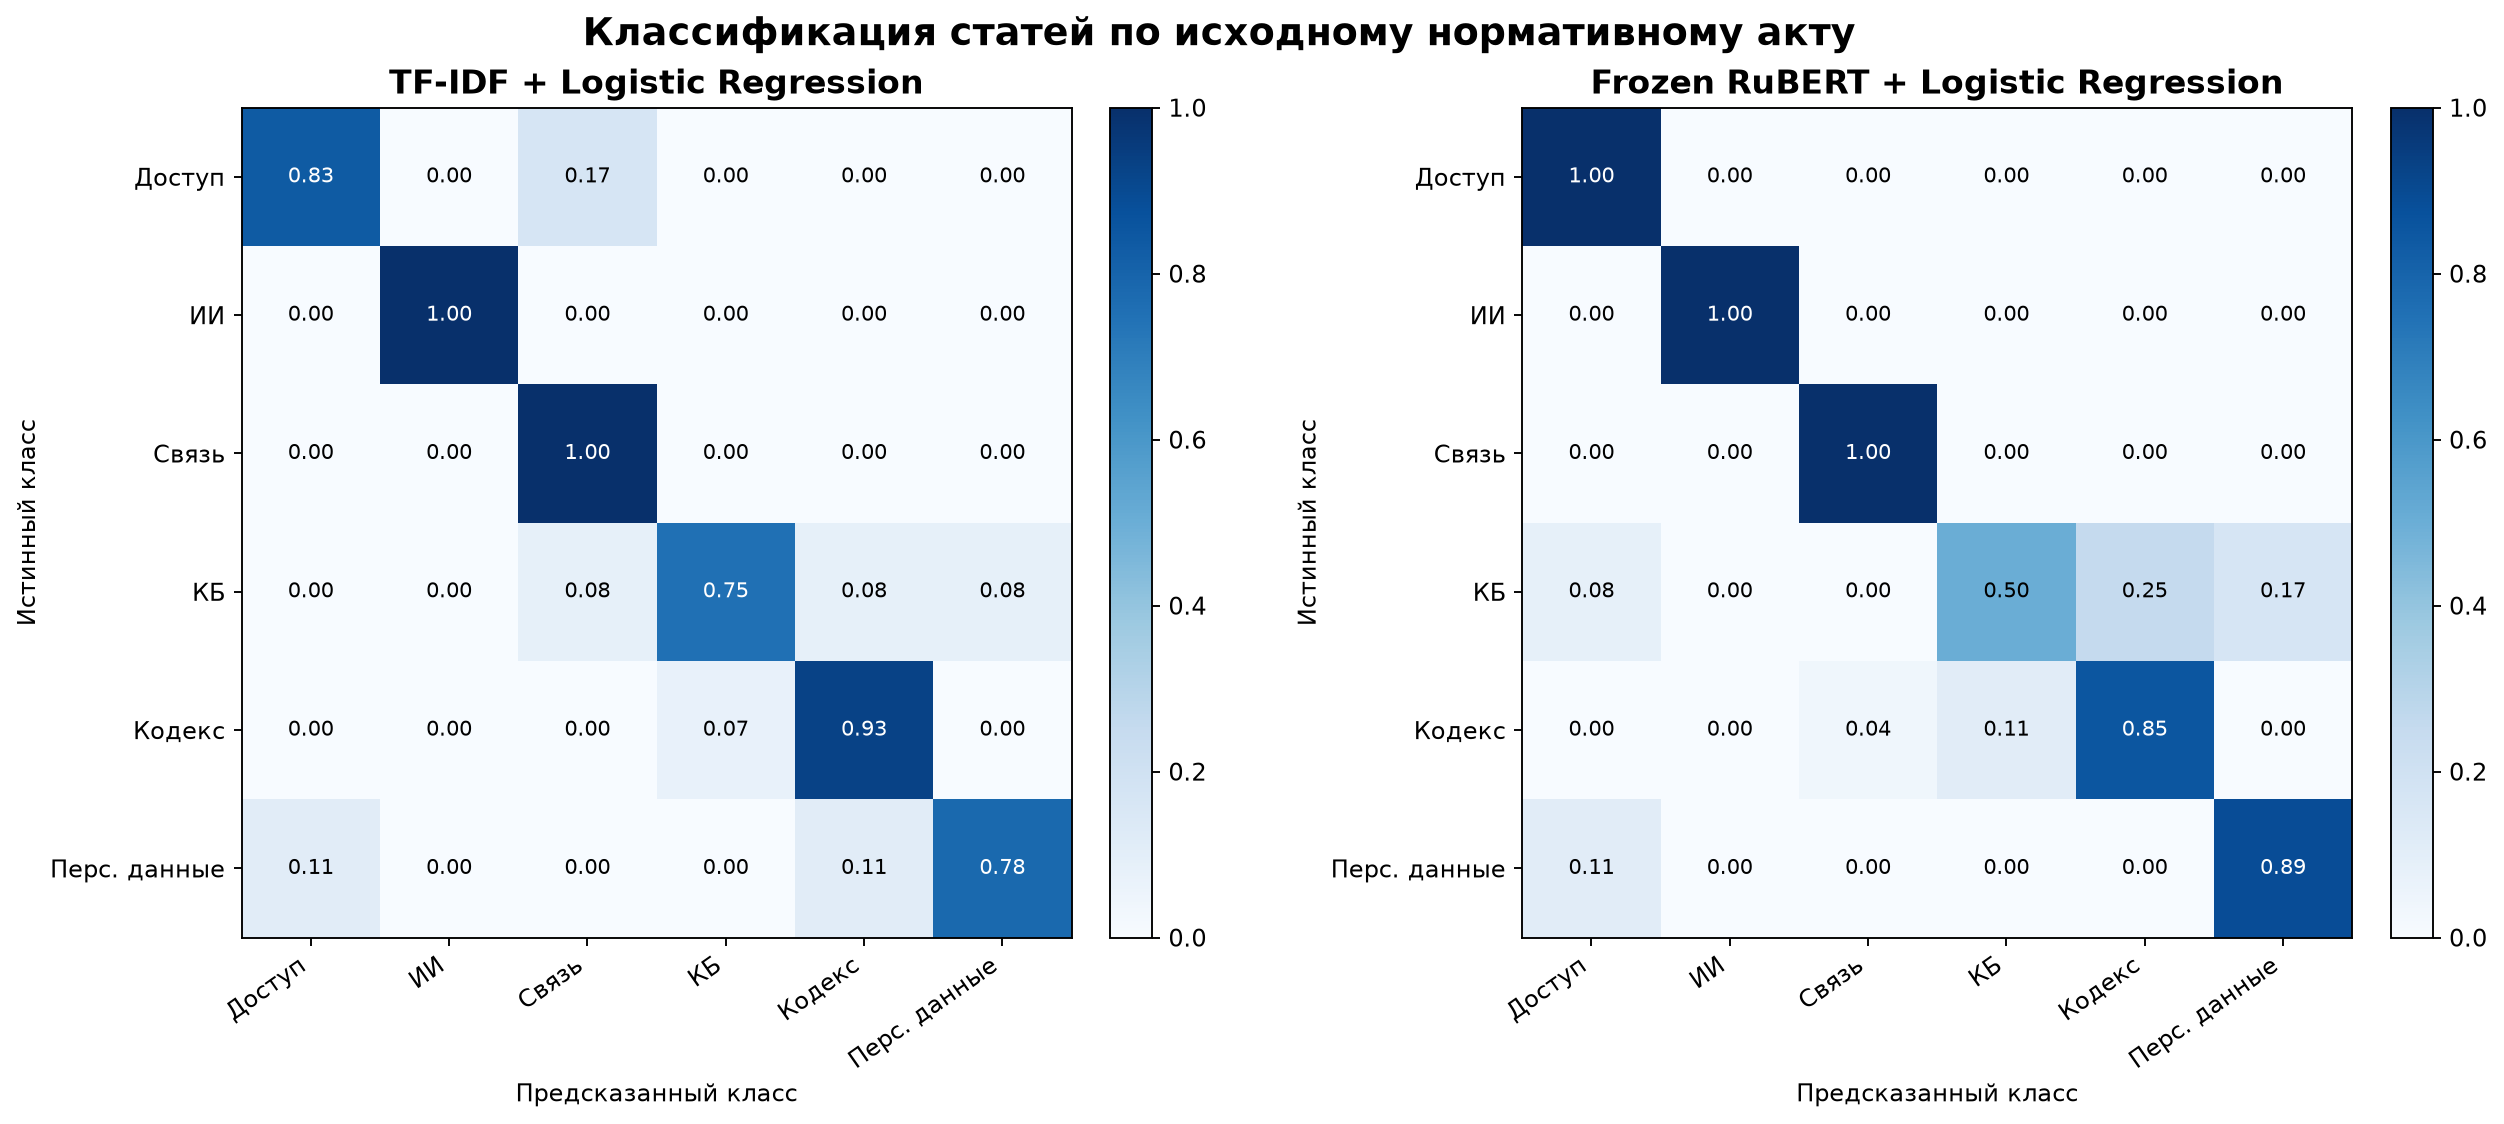

In [4]:
display(Image(filename=str(RESULTS_DIR / "confusion_matrices.png"), width=1100))

## 4. Метрики отдельных классов

In [5]:
per_class = pd.read_csv(RESULTS_DIR / "per_class_metrics.csv")
per_class.pivot(index="label_name", columns="model", values="f1").round(4)

model,Frozen RuBERT + Logistic Regression,TF-IDF + Logistic Regression
label_name,,
Доступ к информации,0.8571,0.8333
Искусственный интеллект,1.0000,1.0000
Кибербезопасность,0.5714,0.7826
Персональные данные,0.8421,0.8235
Связь,0.9697,0.9412
Цифровой кодекс,0.8679,0.9259


## 5. Примеры ошибок

In [6]:
predictions = pd.read_csv(RESULTS_DIR / "test_predictions.csv")
errors = predictions.loc[
    ~predictions["bert_correct"],
    ["article_id", "true_label", "bert_prediction", "preview"],
]
errors.head(10)

,article_id,true_label,bert_prediction,preview
1,personal_data:4,personal_data,access_to_information,1. Законодательство Республики Казахстан о пер...
14,cybersecurity:48,cybersecurity,personal_data,1. Деятельность в сфере обеспечения кибербезоп...
15,cybersecurity:52,cybersecurity,digital_code,1. Журналирование цифровых событий обеспечивае...
16,cybersecurity:75,cybersecurity,digital_code,1. Защитой цифровых объектов является реализац...
18,cybersecurity:79,cybersecurity,personal_data,"Собственники и владельцы цифровых систем, соде..."
19,cybersecurity:83,cybersecurity,digital_code,1. Согласование технического задания на создан...
20,cybersecurity:86,cybersecurity,access_to_information,1. Профилактический контроль без посещения суб...
41,digital_code:92,digital_code,cybersecurity,"Цифровые объекты, предназначенные для реализац..."
44,digital_code:97,digital_code,cybersecurity,1. Кибербезопасность – состояние защищенности ...
45,digital_code:99,digital_code,cybersecurity,1. Испытания цифровых объектов на соответствие...
